# PAI · Deep Learning para Finanzas
## Práctica por capítulos 7–11 e integración con agente Paper para 15 activos

**Alumno:** Juan Fernando Castrejón Villa  
**Matrícula:** 81901  
**Correo:** jcv81901@lasallebajio.edu.mx  
**Carrera y semestre:** Actuaría · 5.º  
**Institución:** Universidad De La Salle Bajío  
**Materia:** Gestión de bases de datos  
**Profesor:** Rubén Miguel Rodríguez Rangel  
**Fecha:** 20 de noviembre de 2026

Este cuaderno adapta el proyecto al protocolo de 15 páginas proporcionado y a la aclaración de incluir **15 activos**. Conserva la relación con los capítulos 7–11 y sustituye, para la práctica final, los objetivos anteriores en diferencias absolutas por el **rendimiento del siguiente día**.

**Estado verificable:** el código y las pruebas están implementados. Los modelos profundos solo se entrenan si Colab demuestra una T4 real. Sin datos válidos o T4, se registra el incidente y el entrenamiento permanece detenido. Una celda ejecutada que informa «pendiente» no acredita el experimento que falta. Los avances anteriores en CPU se conservan como anexo y no sustituyen esta evidencia.

## Antes de ejecutar

1. Subir este `.ipynb` a Google Colab y seleccionar **Entorno de ejecución → Cambiar tipo de entorno → T4**.
2. Ejecutar en orden. La primera celda incluye el código del proyecto y permite guardarlo directamente en Drive para conservar checkpoints fuera del almacenamiento temporal. La autorización de Drive ocurre en tu sesión.
3. Mantener los 15 símbolos para completar todos los modelos, o ejecutar un subconjunto por sesión. Cada activo conserva sus archivos y su evaluación de TE.
4. Al terminar, exportar los resultados e importarlos en la aplicación del ZIP. La interfaz y Ollama pueden ejecutarse en el equipo local.

La práctica usa 100,000 cotizados y 0.10% por lado; el agente usa 50,000 USDT y costo Paper de 0%. Estos supuestos se mantienen separados. La rentabilidad y la mejora frente a lineal deben medirse, no presuponerse.

In [2]:
import os,sys,io,base64,hashlib,zipfile,importlib.util,subprocess
from pathlib import Path
from tempfile import NamedTemporaryFile
def existe(modulo):
    try:return importlib.util.find_spec(modulo) is not None
    except ModuleNotFoundError:return False
EN_COLAB=existe('google.colab')
GUARDAR_EN_DRIVE=True
if EN_COLAB and GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_PROYECTO=Path('/content/drive/MyDrive/PAI_81901')
else:
    RUTA_PROYECTO=Path(os.environ.get('PAI_PROJECT_ROOT',str(Path.cwd()/'PAI_81901'))).resolve()
RUTA_PROYECTO.mkdir(parents=True,exist_ok=True)
CODIGO_BASE64 = '...'
paquete=base64.b64decode(CODIGO_BASE64)
assert hashlib.sha256(paquete).hexdigest()=='aec6aaff3935f3a69063392971d86c35f10d0bac5f2a59dbdf3e050de31df31c'
with zipfile.ZipFile(io.BytesIO(paquete)) as z:
    for archivo in z.infolist():
        destino=(RUTA_PROYECTO/archivo.filename).resolve()
        if not destino.is_relative_to(RUTA_PROYECTO.resolve()):raise RuntimeError('Ruta del paquete no válida.')
        datos_archivo=z.read(archivo)
        if destino.exists():
            existente=destino.read_bytes()
            if existente==datos_archivo:
                continue
            if archivo.filename!='pai/data.py' or hashlib.sha256(existente).hexdigest()!='40676386709d2df16b3c5269904e3fa1ce76d6af725a91b04ef33af104008bdd':
                raise RuntimeError(f'Ya existe otra versión en {destino}. Usa una carpeta nueva para conservar los resultados anteriores.')
        destino.parent.mkdir(parents=True,exist_ok=True)
        temporal=None
        try:
            with NamedTemporaryFile(dir=destino.parent,delete=False) as archivo_temporal:
                temporal=Path(archivo_temporal.name)
                archivo_temporal.write(datos_archivo)
            temporal.replace(destino)
        finally:
            if temporal is not None:
                temporal.unlink(missing_ok=True)
requisitos={'numpy':'numpy>=1.26,<3','pandas':'pandas>=2.2,<3','sklearn':'scikit-learn>=1.6,<2',
 'matplotlib':'matplotlib>=3.8,<4','httpx':'httpx[socks]>=0.27,<1','joblib':'joblib>=1.4,<2',
 'pytest':'pytest>=8,<10','fastapi':'fastapi>=0.115,<1','uvicorn':'uvicorn>=0.30,<1'}
faltantes=[p for m,p in requisitos.items() if not existe(m)]
if EN_COLAB and not existe('tensorflow'):faltantes.append('tensorflow>=2.16,<2.21')
if faltantes:subprocess.check_call([sys.executable,'-m','pip','install','-q',*faltantes])
sys.path.insert(0,str(RUTA_PROYECTO));os.chdir(RUTA_PROYECTO)
print('Proyecto:',RUTA_PROYECTO,'| Google Colab:',EN_COLAB)
print('Código incluido e integridad comprobada. Los modelos no se entrenan en CPU como sustituto de T4.')

Mounted at /content/drive
Proyecto: /content/drive/MyDrive/PAI_81901 | Google Colab: True
Código incluido e integridad comprobada. Los modelos no se entrenan en CPU como sustituto de T4.


In [3]:
import json,time,runpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from pai.config import ROOT,project,symbols,PaiError,save_json
from pai.data import download,audit,rows_frame,DAY_MS
from pai.features import samples,indicators,validate_shape
from pai.training import classical,require_t4,train_asset,incident
CONFIG=project()
ACTIVOS=symbols()  # Puede reducirse por sesión; el catálogo completo conserva 15.
ACTIVO_A_MOSTRAR='BTCUSDT'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
display(pd.DataFrame(CONFIG['assets']))
print('Configurados:',len(symbols()),'| Seleccionados para esta sesión:',len(ACTIVOS))

,symbol,base,name
0,BTCUSDT,BTC,Bitcoin
1,ETHUSDT,ETH,Ethereum
2,SOLUSDT,SOL,Solana
3,XRPUSDT,XRP,XRP
4,ADAUSDT,ADA,Cardano
5,DOGEUSDT,DOGE,Dogecoin
6,AVAXUSDT,AVAX,Avalanche
7,DOTUSDT,DOT,Polkadot
8,LINKUSDT,LINK,Chainlink
9,LTCUSDT,LTC,Litecoin


Configurados: 15 | Seleccionados para esta sesión: 15


## Capítulo 7 · Datos, auditoría y referencias

**Qué se implementó:** descarga de velas diarias MEXC, copia original con metadatos, auditoría, ventanas y referencias cero/lineal. **Por qué:** un error de cronología o escala invalida la comparación de cualquier red. **Evidencia:** archivos originales, hashes, fechas, tabla TR/VA/TE y métricas TR/VA cuando la fuente esté disponible. **Qué revisar después:** periodos nuevos y estabilidad, manteniendo TE reservado.

Se requieren **1,500 observaciones válidas antes de las ventanas**. La fuente debe proporcionar OHLCV; no se inventan volumen ni días. Se ordena y conserva la última respuesta por apertura duplicada, registrando cuántas cambian. Los precios no positivos, infinitos, huecos del calendario o formas incorrectas detienen el proceso. Solo se descartan velas aún abiertas.

Al cierre $t$: $y_t=P_{t+1}/P_t-1$. La entrada contiene los 20 rendimientos conocidos hasta $t$. Las variables técnicas iniciales no se rellenan; ambas versiones usan las mismas fechas evaluables. La separación por fecha objetivo es **70% TR / 15% VA / 15% TE**. Los escaladores solo ven TR. Contexto histórico anterior en VA o TE es válido; etiquetas futuras para ajustar no lo son.

In [4]:
datos_listos = {}
referencias = []
incidentes_datos = []
fallo_global = False

for symbol in ACTIVOS:
    path = ROOT / "data" / "processed" / f"{symbol}.csv"

    if fallo_global and not path.exists():
        incidentes_datos.append({"symbol": symbol, "estado": "Pendiente por un fallo general de MEXC."})
        continue

    try:
        if not path.exists():
            download(symbol, ROOT)
        b, modelos_lineales, tabla = classical(symbol, ROOT)
        datos_listos[symbol] = b
        tabla["symbol"] = symbol
        referencias.append(tabla)
        print(f"{symbol}: datos y referencias listos.")
    except PaiError as exc:
        estado = str(exc)
        incident(ROOT, f"datos_{symbol}", exc, "Revisar la respuesta de MEXC y la auditoría del activo.")
        incidentes_datos.append({"symbol": symbol, "estado": estado})
        fallo_global = fallo_global or estado.startswith((
            "MEXC HTTP 403", "MEXC HTTP 429", "MEXC HTTP 451",
            "MEXC HTTP 5", "MEXC sin respuesta",
        ))

if incidentes_datos:
    display(pd.DataFrame(incidentes_datos))
print(f"Activos con datos auditados: {len(datos_listos)} de {len(ACTIVOS)}")

if any(r["symbol"] == "AVAXUSDT" and r["estado"].startswith("OHLC inconsistente")
       for r in incidentes_datos):
    raw = json.loads((ROOT / "data" / "raw" / "AVAXUSDT.json").read_text(encoding="utf-8"))
    velas = rows_frame(raw["rows"]).drop_duplicates("open_time", keep="last")
    velas["cerrada"] = velas["close_time"] <= raw["server_time"]
    inconsistente = (
        (velas["high"] < velas[["open", "close", "low"]].max(axis=1))
        | (velas["low"] > velas[["open", "close", "high"]].min(axis=1))
    )
    display(velas.loc[inconsistente, ["date", "open", "high", "low", "close", "cerrada"]])

BTCUSDT: datos y referencias listos.
ETHUSDT: datos y referencias listos.
SOLUSDT: datos y referencias listos.
XRPUSDT: datos y referencias listos.
ADAUSDT: datos y referencias listos.
DOGEUSDT: datos y referencias listos.
AVAXUSDT: datos y referencias listos.
DOTUSDT: datos y referencias listos.
LINKUSDT: datos y referencias listos.
LTCUSDT: datos y referencias listos.
BCHUSDT: datos y referencias listos.
XLMUSDT: datos y referencias listos.
TRXUSDT: datos y referencias listos.
ETCUSDT: datos y referencias listos.
ATOMUSDT: datos y referencias listos.
Activos con datos auditados: 15 de 15


In [5]:
from datetime import datetime, timezone
from decimal import Decimal
from pathlib import Path
from tempfile import TemporaryDirectory
import json

import numpy as np
import pandas as pd
from pai.config import ROOT, PaiError, digest, project, save_json
from pai.data import DAY_MS, MexcPublic, audit, rows_frame


def recuperar_avax():
    par, dia = "AVAXUSDT", "2022-12-02"
    inicio = pd.Timestamp(dia, tz="UTC").value // 1_000_000
    ruta_raw = ROOT / "data" / "raw" / f"{par}.json"
    ruta_csv = ROOT / "data" / "processed" / f"{par}.csv"

    if ruta_csv.is_file():
        return

    original = json.loads(ruta_raw.read_text(encoding="utf-8"))
    huella_original = digest(ruta_raw)
    ruta_fuente = ruta_raw.with_name(f"{par}_{dia}_recuperacion.json")
    intentos = []
    recuperada = None
    intervalo_valido = None
    api = MexcPublic()
    try:
        for intervalo, cantidad in (("1d", 1), ("60m", 24), ("4h", 6)):
            consulta = {
                "symbol": par, "interval": intervalo, "limit": cantidad,
                "startTime": inicio, "endTime": inicio + DAY_MS - 1,
            }
            filas = api.get("/api/v3/klines", consulta)
            intentos.append({"consulta": consulta, "velas_originales": filas})
            if (not isinstance(filas, list) or len(filas) != cantidad
                    or not all(isinstance(v, list) and len(v) >= 8 for v in filas)):
                print(f"{intervalo}: MEXC no devolvió las {cantidad} velas requeridas.")
                continue

            partes = rows_frame(filas).sort_values("open_time")
            paso = DAY_MS // cantidad
            esperadas = list(range(inicio, inicio + DAY_MS, paso))
            precios = partes[["open", "high", "low", "close"]]
            volumen = partes[["volume", "quote_volume"]]
            duracion = partes["close_time"] - partes["open_time"]
            horario_valido = partes["open_time"].tolist() == esperadas and duracion.between(paso - 1, paso).all()
            ohlc_valido = (
                np.isfinite(precios.to_numpy()).all()
                and (precios > 0).all().all()
                and precios["high"].ge(precios.max(axis=1)).all()
                and precios["low"].le(precios.min(axis=1)).all()
            )
            if not (horario_valido and ohlc_valido and np.isfinite(volumen.to_numpy()).all()
                    and volumen.ge(0).all().all()):
                print(f"{intervalo}: respuesta con fechas, precios o volúmenes inválidos.")
                continue

            ordenadas = [filas[i] for i in partes.index]
            recuperada = [
                inicio, ordenadas[0][1],
                str(max(Decimal(str(v[2])) for v in ordenadas)),
                str(min(Decimal(str(v[3])) for v in ordenadas)),
                ordenadas[-1][4],
                str(sum(Decimal(str(v[5])) for v in ordenadas)),
                int(ordenadas[-1][6]),
                str(sum(Decimal(str(v[7])) for v in ordenadas)),
            ]
            intervalo_valido = intervalo
            break
    finally:
        api.close()

    save_json(ruta_fuente, {
        "symbol": par, "fecha_utc": dia,
        "source": "https://api.mexc.com/api/v3/klines",
        "downloaded_at": datetime.now(timezone.utc).isoformat(),
        "sha256_raw_original": huella_original,
        "intervalo_usado": intervalo_valido,
        "consultas": intentos, "vela_diaria_recuperada": recuperada,
    })
    if recuperada is None:
        raise PaiError("AVAX sigue pendiente. MEXC no devolvió datos completos y válidos para ese día.")

    filas = [v for v in original["rows"] if int(v[0]) != inicio] + [recuperada]
    datos, reporte = audit(rows_frame(filas), int(original["server_time"]), project()["minimum_observations"])
    ruta_csv.parent.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=ruta_csv.parent) as temporal:
        tmp_csv = Path(temporal) / ruta_csv.name
        tmp_informe = tmp_csv.with_name(f"{par}_auditoria.json")
        datos.to_csv(tmp_csv, index=False)
        reporte.update(
            symbol=par, source="MEXC Spot", quote="USDT",
            downloaded_at=original.get("downloaded_at"), sha256_raw=huella_original,
            sha256_processed=digest(tmp_csv), fecha_recuperada_utc=dia,
            intervalo_recuperacion=intervalo_valido,
            archivo_recuperacion=str(ruta_fuente.relative_to(ROOT)),
            sha256_recuperacion=digest(ruta_fuente),
        )
        save_json(tmp_informe, reporte)
        tmp_informe.replace(ruta_csv.with_name(tmp_informe.name))
        tmp_csv.replace(ruta_csv)

    print(f"{par} auditado con {len(datos)} velas válidas. Se recuperó {dia} con datos de {intervalo_valido}.")
    display(datos.loc[datos["open_time"].eq(inicio), ["date", "open", "high", "low", "close"]])


recuperar_avax()

if "AVAXUSDT" not in datos_listos:
    serie_avax, _, tabla_avax = classical("AVAXUSDT", ROOT)
    tabla_avax["symbol"] = "AVAXUSDT"
    datos_listos["AVAXUSDT"] = serie_avax
    referencias.append(tabla_avax)
    incidentes_datos[:] = [r for r in incidentes_datos if r["symbol"] != "AVAXUSDT"]

print(f"Activos con datos auditados: {len(datos_listos)} de {len(ACTIVOS)}")

Activos con datos auditados: 15 de 15


In [6]:
if referencias:display(pd.concat(referencias,ignore_index=True))
else:display(Markdown('**Referencias pendientes:** no hay muestra MEXC auditada. No se muestran métricas inventadas.'))
for symbol in datos_listos:
    display(Markdown('### '+symbol+' · particiones por fecha objetivo'))
    display(pd.read_csv(ROOT/'artifacts'/symbol/'particiones.csv'))
    display(pd.read_csv(ROOT/'artifacts'/symbol/'ejemplos_alineacion.csv'))
    break

,modelo,variables,conjunto,n,mae,rmse,acierto_direccional,pred_std,real_std,symbol
0,Lineal,base,TR,1721,0.022924,0.034052,0.531668,0.004954,0.034410,BTCUSDT
1,Lineal,base,VA,369,0.016295,0.022297,0.531165,0.003326,0.022245,BTCUSDT
2,Lineal,indicadores,TR,1721,0.022702,0.033286,0.545032,0.008726,0.034410,BTCUSDT
3,Lineal,indicadores,VA,369,0.016531,0.022771,0.493225,0.004548,0.022245,BTCUSDT
4,Cero,base,TR,1721,0.022956,0.034464,0.000000,0.000000,0.034410,BTCUSDT
...,...,...,...,...,...,...,...,...,...,...
85,Lineal,base,VA,369,0.034628,0.048751,0.504065,0.007243,0.048081,ATOMUSDT
86,Lineal,indicadores,TR,1721,0.040178,0.057523,0.536316,0.014607,0.059349,ATOMUSDT
87,Lineal,indicadores,VA,369,0.035169,0.048977,0.514905,0.011563,0.048081,ATOMUSDT
88,Cero,base,TR,1721,0.040741,0.059382,0.001162,0.000000,0.059349,ATOMUSDT


### BTCUSDT · particiones por fecha objetivo

,conjunto,n,primer_objetivo,ultimo_objetivo
0,TR,1721,2020-02-27 00:00:00+00:00,2024-11-12 00:00:00+00:00
1,VA,369,2024-11-13 00:00:00+00:00,2025-11-16 00:00:00+00:00
2,TE,369,2025-11-17 00:00:00+00:00,2026-11-20 00:00:00+00:00


,origin_index,issue_date,target_date,execution_date,input_first_date,input_last_date,close_t,open_next,close_next,sma20,vol20,dist_sma20
0,1759,2024-11-11 00:00:00+00:00,2024-11-12 00:00:00+00:00,2024-11-11 00:00:00+00:00,2024-10-23 00:00:00+00:00,2024-11-11 00:00:00+00:00,80372.02,80372.02,88647.99,70965.2350,0.027315,0.132555
1,1760,2024-11-12 00:00:00+00:00,2024-11-13 00:00:00+00:00,2024-11-12 00:00:00+00:00,2024-10-24 00:00:00+00:00,2024-11-12 00:00:00+00:00,88647.99,88647.99,87952.01,72026.3345,0.034316,0.230772
2,2128,2025-11-15 00:00:00+00:00,2025-11-16 00:00:00+00:00,2025-11-15 00:00:00+00:00,2025-10-27 00:00:00+00:00,2025-11-15 00:00:00+00:00,94559.30,94559.30,95593.29,105939.5745,0.023507,-0.107422
3,2129,2025-11-16 00:00:00+00:00,2025-11-17 00:00:00+00:00,2025-11-16 00:00:00+00:00,2025-10-28 00:00:00+00:00,2025-11-16 00:00:00+00:00,95593.29,95593.29,94258.52,104991.2685,0.022576,-0.089512


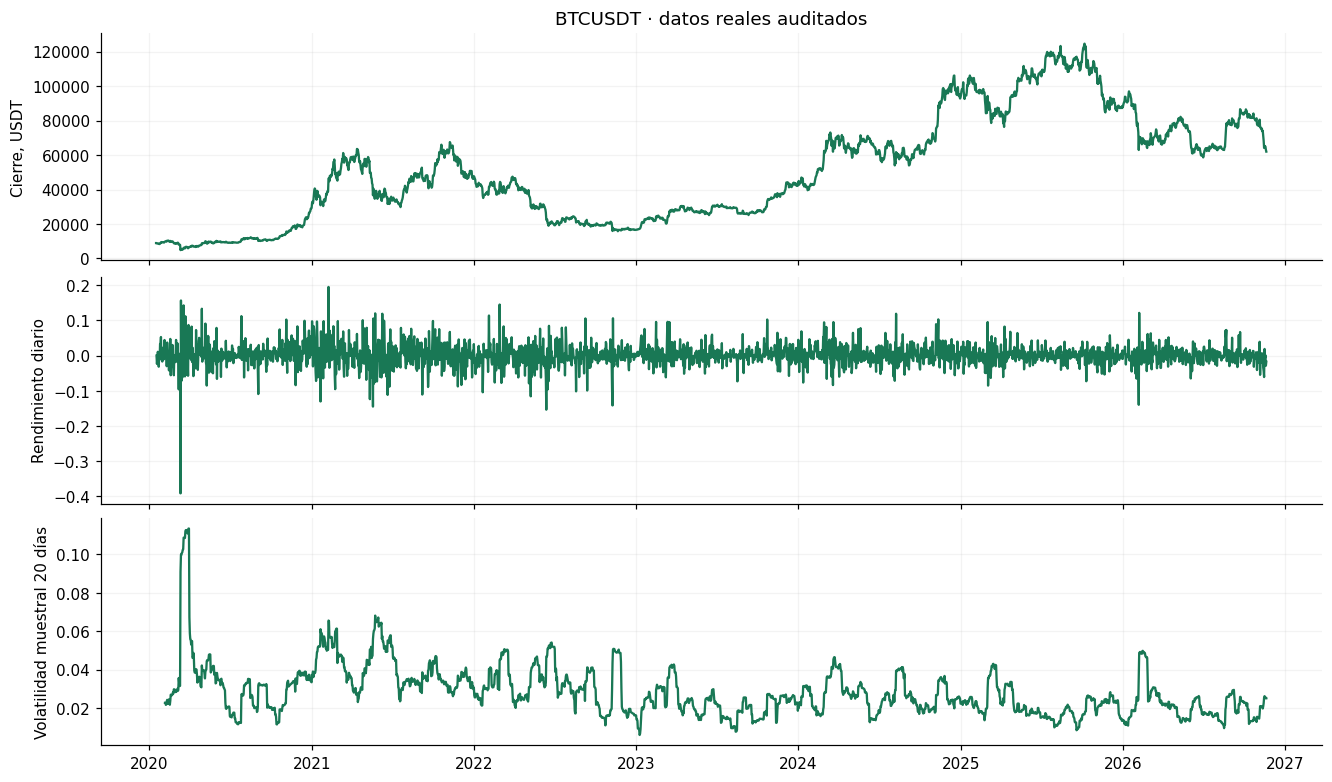

In [7]:
if ACTIVO_A_MOSTRAR in datos_listos:
    f=datos_listos[ACTIVO_A_MOSTRAR]['frame'];fig,ax=plt.subplots(3,1,figsize=(12,7),sharex=True,layout='constrained')
    for a,col,label in zip(ax,['close','return','vol20'],['Cierre, USDT','Rendimiento diario','Volatilidad muestral 20 días']):
        a.plot(pd.to_datetime(f.date),f[col],color='#197855');a.set_ylabel(label)
    ax[0].set_title(ACTIVO_A_MOSTRAR+' · datos reales auditados');plt.show()
else:print('Gráficas financieras pendientes de la descarga válida; no se sustituyen por una curva ficticia.')

### Hipótesis técnica

La distancia a SMA20 y la volatilidad móvil podrían aportar información al pronóstico que no esté resumida por los 20 retornos. Se contrasta el mismo modelo con y sin esas variables en las mismas fechas de VA. Separadamente, se comprueba si exigir cierre sobre SMA20 cambia el resultado de la estrategia. Un filtro modifica operaciones, no MAE ni RMSE de las predicciones originales.

## Capítulo 8 · MLP, LSTM y evidencia de T4

Se implementan MLP y LSTM. Ambas usan MSE, Adam a 0.001, lote 64, máximo 60 épocas, parada temprana con paciencia 8 y restauración del mejor punto de VA. Se varían solo las unidades de la primera capa entre 16, 32 y 64; la capa densa adicional tiene 8. La LSTM recibe **ejemplos × 20 pasos × variables**.

La mejor configuración base de cada familia se repite con tres semillas (123, 7, 42). Se reporta media y desviación; la semilla de uso final es **123 predefinida**, evitando seleccionar una semilla favorable. Se añaden las versiones con indicadores y se selecciona con RMSE de VA. Las curvas, tiempos, parámetros, dispositivo y versiones se exportan.

La evidencia incluye `nvidia-smi`, detección del framework, una multiplicación en GPU y ubicación de los pesos durante entrenamiento. **Sin T4 real de Colab, esta etapa se detiene.** La GPU del menú por sí sola no basta.

In [8]:
tf=None;evidencia_gpu=None
try:
    tf,evidencia_gpu=require_t4(ROOT)
    print(evidencia_gpu['nvidia_smi']);print('Operación:',evidencia_gpu['operation_device'])
except PaiError as exc:
    display(Markdown('**Entrenamiento profundo detenido:** '+str(exc)))
    print('Se registró el incidente. No se utiliza CPU como sustituto de la T4 requerida.')

Sun Nov 22 17:59:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:
EJECUTAR_ENTRENAMIENTO=True
entrenados=[]
if tf is not None and evidencia_gpu is not None and EJECUTAR_ENTRENAMIENTO:
    for symbol in ACTIVOS:
        if symbol not in datos_listos:continue
        if (ROOT/'artifacts'/symbol/'evaluacion_TE.lock.json').exists():
            print(symbol,': evaluación ya reservada o concluida. Se conserva sin reabrir la selección.');continue
        try:
            manifest=train_asset(symbol,tf,evidencia_gpu,ROOT);entrenados.append(symbol)
            print(symbol,': finalizado y guardado; selección congelada y TE evaluado una vez.')
        except PaiError as exc:
            incident(ROOT,'entrenamiento_'+symbol,exc,'Conservar registros y corregir la dependencia antes de continuar.')
            raise
else:print('No se entrenó ninguna red: T4 ausente, entrenamiento desactivado o datos pendientes.')

BTCUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
ETHUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
SOLUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
XRPUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
ADAUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
DOGEUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
AVAXUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
DOTUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
LINKUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
LTCUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
BCHUSDT : evaluación ya reservada o concluida. Se conserva sin reabrir la selección.
XLMUSDT : evaluación ya reservada o concluida. Se conserva sin

In [16]:
def reunir(nombre):
    tablas = []
    for symbol in ACTIVOS:
        ruta = ROOT / "artifacts" / symbol / nombre
        if not ruta.is_file():
            continue
        tabla = pd.read_csv(ruta)
        if "symbol" not in tabla.columns:
            tabla.insert(0, "symbol", symbol)
        tablas.append(tabla)
    return pd.concat(tablas, ignore_index=True) if tablas else pd.DataFrame()


experimentos = reunir("experimentos.csv")
semillas = reunir("resumen_semillas.csv")

if not experimentos.empty:
    display(experimentos)
else:
    print("Los experimentos aparecerán después del entrenamiento.")

if not semillas.empty:
    display(semillas)

,symbol,id,capitulo,modelo,variables,conjunto,seed,neuronas,device,seconds,...,best_epoch,parametros_entrenables,model_sha256,transformaciones,n,mae,rmse,acierto_direccional,pred_std,real_std
0,BTCUSDT,MLP_base_n16_s123,8,MLP,base,TR,123,16,/GPU:0,7.794043,...,18,481,ab6542d56e6a987f28de2ec531e4933ca630cedafac093...,StandardScaler X e y; ajuste solo TR,1721,0.022616,0.033458,0.553167,0.006836,0.034410
1,BTCUSDT,MLP_base_n16_s123,8,MLP,base,VA,123,16,/GPU:0,7.794043,...,18,481,ab6542d56e6a987f28de2ec531e4933ca630cedafac093...,StandardScaler X e y; ajuste solo TR,369,0.016610,0.022901,0.517615,0.004222,0.022245
2,BTCUSDT,MLP_base_n32_s123,8,MLP,base,TR,123,32,/GPU:0,4.061604,...,8,945,399e32d3ebc3cc91e40f14c6c89957f74478fcb20d53d7...,StandardScaler X e y; ajuste solo TR,1721,0.022668,0.033511,0.556072,0.007740,0.034410
3,BTCUSDT,MLP_base_n32_s123,8,MLP,base,VA,123,32,/GPU:0,4.061604,...,8,945,399e32d3ebc3cc91e40f14c6c89957f74478fcb20d53d7...,StandardScaler X e y; ajuste solo TR,369,0.016648,0.022744,0.539295,0.005165,0.022245
4,BTCUSDT,MLP_base_n64_s123,8,MLP,base,TR,123,64,/GPU:0,4.607005,...,4,1873,2559f0547b9af16e05a50c248743cfb51da42e70a1f57a...,StandardScaler X e y; ajuste solo TR,1721,0.022640,0.033415,0.552005,0.008155,0.034410
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,ATOMUSDT,LSTM_base_n64_s7,8,LSTM,base,VA,7,64,/GPU:0,5.476595,...,12,17425,b5d5887d56344e3a8d0cb2f9f4fbfd093d327f07f7ef0a...,StandardScaler X e y; ajuste solo TR,369,0.033887,0.047585,0.501355,0.005410,0.048081
356,ATOMUSDT,LSTM_base_n64_s42,8,LSTM,base,TR,42,64,/GPU:0,4.761173,...,5,17425,a1cb88bf90c10f6995a8109821d455fdeca85f51a24f8b...,StandardScaler X e y; ajuste solo TR,1721,0.040506,0.058865,0.507844,0.003710,0.059349
357,ATOMUSDT,LSTM_base_n64_s42,8,LSTM,base,VA,42,64,/GPU:0,4.761173,...,5,17425,a1cb88bf90c10f6995a8109821d455fdeca85f51a24f8b...,StandardScaler X e y; ajuste solo TR,369,0.034074,0.047980,0.487805,0.003120,0.048081
358,ATOMUSDT,LSTM_indicadores_n64_s123,11,LSTM,indicadores,TR,123,64,/GPU:0,3.624476,...,4,17937,a2fc087c8971c8506ade95dd32b577bf5ddb3466d8bcb5...,StandardScaler X e y; ajuste solo TR,1721,0.040284,0.058631,0.529343,0.005905,0.059349


,symbol,modelo,neuronas,n_semillas,rmse_media,rmse_sd,mae_media,mae_sd
0,BTCUSDT,MLP,32,3,0.022748,0.000048,0.016683,0.000034
1,BTCUSDT,LSTM,32,3,0.022265,0.000015,0.016126,0.000015
2,ETHUSDT,MLP,16,3,0.040407,0.000533,0.028696,0.000465
3,ETHUSDT,LSTM,16,3,0.039494,0.000071,0.027825,0.000099
4,SOLUSDT,MLP,32,3,0.047075,0.000149,0.034726,0.000206
5,SOLUSDT,LSTM,32,3,0.045763,0.000297,0.033368,0.000212
6,XRPUSDT,MLP,64,3,0.051803,0.000424,0.034283,0.000292
7,XRPUSDT,LSTM,16,3,0.051744,0.000484,0.034008,0.000110
8,ADAUSDT,MLP,32,3,0.062914,0.000132,0.038516,0.000259
9,ADAUSDT,LSTM,16,3,0.061530,0.000063,0.036498,0.000131


,familia,neuronas,parametros_entrenables,learning_rate,batch_size,epochs,best_epoch,device,seconds
0,LSTM,32,4625,0.001,64,15,7,/GPU:0,5.429664


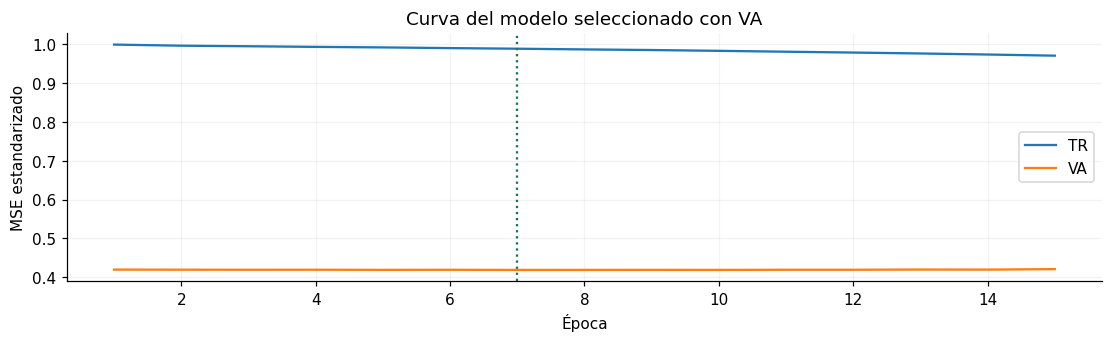

In [11]:
carpeta=ROOT/'artifacts'/ACTIVO_A_MOSTRAR
man_path=carpeta/'manifest.json'
if man_path.exists():
    m=json.loads(man_path.read_text());d=m['training']
    display(pd.DataFrame([{k:d[k] for k in ['familia','neuronas','parametros_entrenables','learning_rate','batch_size','epochs','best_epoch','device','seconds']}]))
    h=pd.read_csv(carpeta/m['selected_experiment']/'historial.csv')
    fig,ax=plt.subplots(figsize=(10,3),layout='constrained');ax.plot(h.index+1,h.loss,label='TR');ax.plot(h.index+1,h.val_loss,label='VA')
    ax.axvline(d['best_epoch'],ls=':',color='#187552');ax.set(xlabel='Época',ylabel='MSE estandarizado',title='Curva del modelo seleccionado con VA');ax.legend();plt.show()
else:print('Arquitectura entrenada y curvas pendientes de T4.')

## Capítulo 9 · Validación temporal y umbrales

Se implementan **tres ventanas expansivas dentro de TR**. El entrenamiento de cada bloque y la validación interna para parada temprana terminan antes del tramo evaluado. Los escaladores se reajustan únicamente en ese entrenamiento. VA permanece para la selección final y TE no interviene.

Se prefijan cinco umbrales positivos: 0.0005, 0.001, 0.002, 0.005 y 0.01. Se compara comprar cuando el pronóstico supera el umbral contra la misma regla con cierre por encima de SMA20. Se selecciona por rendimiento neto de VA y, en empate, menor drawdown. Un umbral de retorno no es una probabilidad.

La diferenciación fraccionaria busca estabilizar niveles preservando memoria. Aquí el objetivo ya son retornos y se usa una ventana corta; añadir otra transformación sin validación no acredita mejora. Su implementación y los pronósticos multiperíodo son opcionales en este protocolo y se mantienen fuera de los requisitos mínimos.

In [12]:
folds=reunir('ventanas_expansivas_TR.csv');umbrales=reunir('umbrales_VA.csv')
if not folds.empty:display(folds)
else:print('Ventanas expansivas pendientes: se calculan con el modelo profundo en T4.')
if not umbrales.empty:display(umbrales)
else:display(pd.DataFrame({'umbrales_predefinidos':CONFIG['thresholds']}))

,symbol,fold,n_ajuste,ultimo_entrenamiento,primer_evaluado,ultimo_evaluado,n,mae,rmse,acierto_direccional,pred_std,real_std
0,BTCUSDT,1,366,2021-02-26 00:00:00+00:00,2021-05-03 00:00:00+00:00,2022-07-06 00:00:00+00:00,430,0.029010,0.039626,0.493023,0.000986,0.038955
1,BTCUSDT,2,731,2022-02-26 00:00:00+00:00,2022-07-07 00:00:00+00:00,2023-09-09 00:00:00+00:00,430,0.017569,0.026305,0.460465,0.000679,0.026244
2,BTCUSDT,3,1097,2023-02-27 00:00:00+00:00,2023-09-10 00:00:00+00:00,2024-11-12 00:00:00+00:00,430,0.018797,0.026683,0.532558,0.000884,0.026685
3,ETHUSDT,1,366,2021-02-26 00:00:00+00:00,2021-05-03 00:00:00+00:00,2022-07-06 00:00:00+00:00,430,0.038078,0.052024,0.509302,0.001617,0.051381
4,ETHUSDT,2,731,2022-02-26 00:00:00+00:00,2022-07-07 00:00:00+00:00,2023-09-09 00:00:00+00:00,430,0.023214,0.034713,0.476744,0.001534,0.034736
5,ETHUSDT,3,1097,2023-02-27 00:00:00+00:00,2023-09-10 00:00:00+00:00,2024-11-12 00:00:00+00:00,430,0.021797,0.031443,0.544186,0.001320,0.031503
6,SOLUSDT,1,340,2021-07-23 00:00:00+00:00,2021-09-22 00:00:00+00:00,2022-10-26 00:00:00+00:00,400,0.044361,0.057564,0.480000,0.001666,0.055882
7,SOLUSDT,2,680,2022-06-28 00:00:00+00:00,2022-10-27 00:00:00+00:00,2023-11-30 00:00:00+00:00,400,0.038601,0.058446,0.485000,0.011410,0.057709
8,SOLUSDT,3,1020,2023-06-03 00:00:00+00:00,2023-12-01 00:00:00+00:00,2025-01-03 00:00:00+00:00,400,0.034925,0.044774,0.485000,0.004421,0.044525
9,XRPUSDT,1,366,2021-02-26 00:00:00+00:00,2021-05-03 00:00:00+00:00,2022-07-06 00:00:00+00:00,430,0.040080,0.057166,0.493023,0.002464,0.056720


,symbol,delta,filtro_sma20,rendimiento_neto,max_drawdown,operaciones_cerradas,win_rate,costos_totales,patrimonio_final
0,BTCUSDT,0.0010,False,0.159872,0.276096,9,0.444444,2020.091139,115987.200549
1,BTCUSDT,0.0005,False,0.076192,0.280953,1,1.000000,207.627068,107619.241469
2,BTCUSDT,0.0020,False,0.041458,0.233259,17,0.647059,3349.106787,104145.773046
3,BTCUSDT,0.0010,True,0.008590,0.192435,20,0.250000,4330.021036,100859.028077
4,BTCUSDT,0.0100,False,0.000000,0.000000,0,NaN,0.000000,100000.000000
...,...,...,...,...,...,...,...,...,...
145,ATOMUSDT,0.0005,False,0.356347,0.368403,16,0.437500,4153.317336,135634.652136
146,ATOMUSDT,0.0050,True,0.316768,0.098858,7,0.714286,1738.331827,131676.794956
147,ATOMUSDT,0.0100,False,0.200489,0.083566,8,0.625000,1714.736947,120048.880793
148,ATOMUSDT,0.0005,True,0.040354,0.392672,10,0.300000,2513.972779,104035.390860


### Emisión, ejecución y costos

La práctica académica parte de 100,000 unidades cotizadas, compra o efectivo sin cortos y costo de 0.10% por cada lado. Se emite al cierre $t$, se ejecuta en la apertura $t+1$ y se valora al cierre $t+1$. Se cobra solo al operar, no se recompra diariamente una posición abierta y se liquida al último cierre. Comprar y mantener y efectivo usan las mismas fechas. `Win Rate` corresponde a operaciones cerradas positivas después de costos; si no hay cierres, no está definido.

## Capítulo 10 · Diseño del entorno y transición

El estado contiene retornos recientes, pronóstico, indicadores, efectivo, posición y patrimonio. Las acciones son **comprar, mantener o vender una posición existente**; mantener una posición y permanecer en efectivo se distinguen por la posición actual. Se bloquean apalancamiento, cortos, compras sin saldo, exposición excesiva y pérdidas diarias.

La recompensa propuesta es $E_{nuevo}-E_{anterior}$ después de costos, valorada tras la ejecución y el siguiente cierre. El pronóstico estima un retorno; la señal aplica una regla; una política aprendida asigna acciones a estados mediante experiencia y recompensa. El agente Ollama de este proyecto es un coordinador con controles, **no un DQN entrenado**. El protocolo no exige entrenar DQN/DDQN completo en la práctica.

En DQN, la exploración permite probar acciones, la memoria reutiliza transiciones y una red objetivo estabiliza las metas. DDQN separa selección de la acción futura y su evaluación. Una política podría explotar un error de contabilidad si se acreditara una ganancia antes del fill; por eso se separan emisión, ejecución, costos y valoración.

In [13]:
# EJERCICIO HIPOTÉTICO, no datos de mercado ni resultado financiero del proyecto.
from decimal import Decimal,ROUND_DOWN
capital=Decimal('50000');apertura=Decimal('100');deslizamiento=Decimal('0.0002')
precio=apertura*(1+deslizamiento);cantidad=(capital*Decimal('0.10')/precio).quantize(Decimal('0.00001'),rounding=ROUND_DOWN)
efectivo=capital-cantidad*precio;cierre=Decimal('101');patrimonio=efectivo+cantidad*cierre
transicion=pd.DataFrame([{'tipo':'Ejemplo hipotético','capital':float(capital),'accion':'BUY',
 'precio_fill':float(precio),'cantidad':float(cantidad),'costo_comision':0.,'efectivo_nuevo':float(efectivo),
 'cierre_siguiente':float(cierre),'patrimonio_nuevo':float(patrimonio),'recompensa':float(patrimonio-capital)}])
display(transicion)

,tipo,capital,accion,precio_fill,cantidad,costo_comision,efectivo_nuevo,cierre_siguiente,patrimonio_nuevo,recompensa
0,Ejemplo hipotético,50000.0,BUY,100.02,49.99,0.0,45000.0002,101.0,50048.9902,48.9902


## Capítulo 11 · Indicadores, diagnóstico y prueba final

Se comparan retornos rezagados con el mismo modelo más dos variables:

| Variable | Definición | Disponibilidad |
|---|---|---|
| Distancia SMA20 | $P_t/\operatorname{SMA}_{20,t}-1$ | Después de 20 cierres |
| Volatilidad 20 | Desviación estándar **muestral**, `ddof=1`, de 20 retornos diarios | Después de 20 retornos |

Las variables se calculan con historia hasta $t$, sin anualizar ni rellenar hacia atrás. Se guarda la primera fecha válida, se revisan correlaciones solo en TR y se mide la dispersión de las predicciones para detectar salidas casi constantes.

Se congela familia, tamaño, variables, semilla, escaladores, umbral y filtro antes de abrir TE. El modelo seleccionado y las referencias finales se evalúan en las mismas fechas una sola vez. Los CSV contienen emisión, objetivo, real, estimado, error = estimado − real y señal. El pronóstico futuro tiene fecha y mantiene el real vacío. COT es opcional y no se utiliza sin calendario verificable de publicación.

In [17]:
for archivo in ['diccionario_indicadores.csv','correlaciones_TR.csv','metricas_finales.csv','prediccion_futura.csv']:
    t=reunir(archivo)
    display(Markdown('### '+archivo))
    if not t.empty:display(t)
    else:print('Pendiente de datos y ejecución del modelo; no se completan cifras artificialmente.')

### diccionario_indicadores.csv

,symbol,variable,formula,ventana,unidad,primera_fecha_valida
0,BTCUSDT,return,close_t / close_t_minus_1 - 1,1,Fracción diaria,2020-01-18 00:00:00+00:00
1,BTCUSDT,dist_sma20,close_t / promedio(20 cierres) - 1,20,Fracción,2020-02-05 00:00:00+00:00
2,BTCUSDT,vol20,"std(20 rendimientos, ddof=1)",20,Fracción diaria sin anualizar,2020-02-06 00:00:00+00:00
3,ETHUSDT,return,close_t / close_t_minus_1 - 1,1,Fracción diaria,2020-01-18 00:00:00+00:00
4,ETHUSDT,dist_sma20,close_t / promedio(20 cierres) - 1,20,Fracción,2020-02-05 00:00:00+00:00
5,ETHUSDT,vol20,"std(20 rendimientos, ddof=1)",20,Fracción diaria sin anualizar,2020-02-06 00:00:00+00:00
6,SOLUSDT,return,close_t / close_t_minus_1 - 1,1,Fracción diaria,2020-07-09 00:00:00+00:00
7,SOLUSDT,dist_sma20,close_t / promedio(20 cierres) - 1,20,Fracción,2020-07-27 00:00:00+00:00
8,SOLUSDT,vol20,"std(20 rendimientos, ddof=1)",20,Fracción diaria sin anualizar,2020-07-28 00:00:00+00:00
9,XRPUSDT,return,close_t / close_t_minus_1 - 1,1,Fracción diaria,2020-01-18 00:00:00+00:00


### correlaciones_TR.csv

,symbol,Unnamed: 0,return,dist_sma20,vol20
0,BTCUSDT,return,1.000000,0.374728,0.007828
1,BTCUSDT,dist_sma20,0.374728,1.000000,-0.142987
2,BTCUSDT,vol20,0.007828,-0.142987,1.000000
3,ETHUSDT,return,1.000000,0.368569,0.010924
4,ETHUSDT,dist_sma20,0.368569,1.000000,-0.142286
5,ETHUSDT,vol20,0.010924,-0.142286,1.000000
6,SOLUSDT,return,1.000000,0.393187,0.068452
7,SOLUSDT,dist_sma20,0.393187,1.000000,0.127537
8,SOLUSDT,vol20,0.068452,0.127537,1.000000
9,XRPUSDT,return,1.000000,0.396284,0.074941


### metricas_finales.csv

,symbol,modelo,conjunto,variables,n,mae,rmse,acierto_direccional,pred_std,real_std
0,BTCUSDT,DL,TR,base,1721,0.022908,0.034161,0.514236,0.002062,0.034410
1,BTCUSDT,DL,VA,base,369,0.016114,0.022269,0.512195,0.000941,0.022245
2,BTCUSDT,DL,TE,base,369,0.016011,0.023053,0.474255,0.001326,0.023045
3,BTCUSDT,Lineal,TR,base,1721,0.022924,0.034052,0.531668,0.004954,0.034410
4,BTCUSDT,Lineal,VA,base,369,0.016295,0.022297,0.531165,0.003326,0.022245
...,...,...,...,...,...,...,...,...,...,...
130,ATOMUSDT,Lineal,VA,base,369,0.034628,0.048751,0.504065,0.007243,0.048081
131,ATOMUSDT,Lineal,TE,base,369,0.026244,0.034973,0.501355,0.005405,0.034337
132,ATOMUSDT,Cero,TR,base,1721,0.040741,0.059382,0.001162,0.000000,0.059349
133,ATOMUSDT,Cero,VA,base,369,0.034190,0.048086,0.005420,0.000000,0.048081


### prediccion_futura.csv

,symbol,fecha_corte,proximo_periodo,estimado,real,senal
0,BTCUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,0.003128,NaN,True
1,ETHUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,0.002477,NaN,True
2,SOLUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,0.003946,NaN,True
3,XRPUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,0.012715,NaN,True
4,ADAUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,-0.002809,NaN,False
5,DOGEUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,0.001882,NaN,False
6,AVAXUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,-0.000998,NaN,False
7,DOTUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,-0.000488,NaN,False
8,LINKUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,-0.000105,NaN,False
9,LTCUSDT,2026-11-20 00:00:00+00:00,2026-11-21 00:00:00+00:00,0.004496,NaN,True


In [18]:
te=reunir('predicciones_TE.csv')
if not te.empty:display(te.head(20))
else:print('TE nuevo de los activos cripto no ha sido evaluado en esta ejecución.')
for symbol in ACTIVOS:
    p=ROOT/'artifacts'/symbol/'criterios_empiricos.json'
    if p.exists():display(Markdown(symbol));display(pd.DataFrame([json.loads(p.read_text())]))
print('La pág. 1 exige +20% y DL > lineal; la pág. 13 dice que no exige rentabilidad positiva para candidatura. Se reportan resultados reales y se conserva la discrepancia para revisión docente.')

,symbol,origin_index,issue_date,target_date,execution_date,input_first_date,input_last_date,close_t,open_next,close_next,sma20,vol20,dist_sma20,modelo,real,estimado,error,senal
0,BTCUSDT,2129,2025-11-16 00:00:00+00:00,2025-11-17 00:00:00+00:00,2025-11-16 00:00:00+00:00,2025-10-28 00:00:00+00:00,2025-11-16 00:00:00+00:00,95593.29,95593.29,94258.52,104991.2685,0.022576,-0.089512,DL,-0.013963,0.001093,0.015056,True
1,BTCUSDT,2130,2025-11-17 00:00:00+00:00,2025-11-18 00:00:00+00:00,2025-11-17 00:00:00+00:00,2025-10-29 00:00:00+00:00,2025-11-17 00:00:00+00:00,94258.52,94258.52,92217.41,103998.8125,0.022574,-0.093658,DL,-0.021654,0.001666,0.023321,True
2,BTCUSDT,2131,2025-11-18 00:00:00+00:00,2025-11-19 00:00:00+00:00,2025-11-18 00:00:00+00:00,2025-10-30 00:00:00+00:00,2025-11-18 00:00:00+00:00,92217.41,92217.41,92961.18,102964.7625,0.022743,-0.104379,DL,0.008065,0.002447,-0.005618,True
3,BTCUSDT,2132,2025-11-19 00:00:00+00:00,2025-11-20 00:00:00+00:00,2025-11-19 00:00:00+00:00,2025-10-31 00:00:00+00:00,2025-11-19 00:00:00+00:00,92961.18,92961.18,91560.76,102111.7570,0.022764,-0.089613,DL,-0.015065,0.000955,0.016019,False
4,BTCUSDT,2133,2025-11-20 00:00:00+00:00,2025-11-21 00:00:00+00:00,2025-11-20 00:00:00+00:00,2025-11-01 00:00:00+00:00,2025-11-20 00:00:00+00:00,91560.76,91560.76,86630.63,101274.0980,0.022757,-0.095911,DL,-0.053845,0.001555,0.055400,True
5,BTCUSDT,2134,2025-11-21 00:00:00+00:00,2025-11-22 00:00:00+00:00,2025-11-21 00:00:00+00:00,2025-11-02 00:00:00+00:00,2025-11-21 00:00:00+00:00,86630.63,86630.63,85125.34,100125.4090,0.024401,-0.134779,DL,-0.017376,0.005195,0.022571,True
6,BTCUSDT,2135,2025-11-22 00:00:00+00:00,2025-11-23 00:00:00+00:00,2025-11-22 00:00:00+00:00,2025-11-03 00:00:00+00:00,2025-11-22 00:00:00+00:00,85125.34,85125.34,84733.13,98877.1915,0.024142,-0.139080,DL,-0.004607,0.003782,0.008390,True
7,BTCUSDT,2136,2025-11-23 00:00:00+00:00,2025-11-24 00:00:00+00:00,2025-11-23 00:00:00+00:00,2025-11-04 00:00:00+00:00,2025-11-23 00:00:00+00:00,84733.13,84733.13,86824.58,97587.2795,0.023908,-0.131720,DL,0.024683,0.002464,-0.022218,True
8,BTCUSDT,2137,2025-11-24 00:00:00+00:00,2025-11-25 00:00:00+00:00,2025-11-24 00:00:00+00:00,2025-11-05 00:00:00+00:00,2025-11-24 00:00:00+00:00,86824.58,86824.58,88293.24,96599.7995,0.024675,-0.101193,DL,0.016915,0.000911,-0.016004,False
9,BTCUSDT,2138,2025-11-25 00:00:00+00:00,2025-11-26 00:00:00+00:00,2025-11-25 00:00:00+00:00,2025-11-06 00:00:00+00:00,2025-11-25 00:00:00+00:00,88293.24,88293.24,87368.99,95940.3425,0.023669,-0.079707,DL,-0.010468,0.000946,0.011414,False


BTCUSDT

,dl_supera_lineal_rmse_TE,rentabilidad_superior_20pct_TE,nota
0,True,False,"Resultados observados, sin ajustar con TE. Pág..."


ETHUSDT

,dl_supera_lineal_rmse_TE,rentabilidad_superior_20pct_TE,nota
0,True,False,"Resultados observados, sin ajustar con TE. Pág..."


SOLUSDT

... (22 outputs left out)

,dl_supera_lineal_rmse_TE,rentabilidad_superior_20pct_TE,nota
0,True,False,"Resultados observados, sin ajustar con TE. Pág..."


ATOMUSDT

,dl_supera_lineal_rmse_TE,rentabilidad_superior_20pct_TE,nota
0,False,False,"Resultados observados, sin ajustar con TE. Pág..."


La pág. 1 exige +20% y DL > lineal; la pág. 13 dice que no exige rentabilidad positiva para candidatura. Se reportan resultados reales y se conserva la discrepancia para revisión docente.


## Manejo de errores · Cuatro fallos provocados

Las siguientes copias sintéticas sirven exclusivamente para comprobar validadores. No se guardan como observaciones de MEXC ni se usan para entrenar. Se conservan mensajes de detención y la fuente original del ejercicio permanece sin cambios.

In [19]:
fechas=pd.date_range('2024-01-01',periods=65,freq='D',tz='UTC');ms=fechas.astype('int64')//10**6
prueba=pd.DataFrame({'date':fechas,'open_time':ms,'close_time':ms+DAY_MS-1,'open':100.,'high':101.,'low':99.,'close':100.,'volume':1.,'quote_volume':100.})
duplicado=pd.concat([prueba,prueba.iloc[[5]]],ignore_index=True)
invalido=prueba.copy();invalido.loc[7,'close']=np.nan
checks=[('Conjunto vacío',lambda:audit(prueba.iloc[:0],int(ms[-1])+DAY_MS,min_rows=10)),
 ('Fecha duplicada',lambda:audit(duplicado,int(ms[-1])+DAY_MS,min_rows=10,repair_duplicates=False)),
 ('Valor no válido',lambda:audit(invalido,int(ms[-1])+DAY_MS,min_rows=10)),
 ('Dimensión incorrecta',lambda:validate_shape(np.ones((5,20)),20,1))]
fallos=[]
for nombre,funcion in checks:
    try:funcion();raise AssertionError('El fallo controlado no fue detectado: '+nombre)
    except PaiError as exc:fallos.append({'caso':nombre,'mensaje':str(exc),'resultado':'Detención esperada'})
display(pd.DataFrame(fallos));assert len(prueba)==65 and prueba.close.notna().all()
pd.DataFrame(fallos).to_csv(ROOT/'evidencia/cuatro_fallos_controlados.csv',index=False)

,caso,mensaje,resultado
0,Conjunto vacío,Conjunto vacío: descarga o archivo sin observa...,Detención esperada
1,Fecha duplicada,Fecha duplicada: se detuvo la copia de prueba.,Detención esperada
2,Valor no válido,"Dato no válido: fecha, faltante, infinito o co...",Detención esperada
3,Dimensión incorrecta,"Dimensiones incorrectas: esperado (ejemplos,20...",Detención esperada


In [20]:
resultado=subprocess.run([sys.executable,'scripts/ejecutar_pruebas.py'],cwd=ROOT,capture_output=True,text=True)
print(resultado.stdout)
if resultado.returncode:raise RuntimeError('Falló una prueba; revisar evidencia/pruebas_salida.txt antes de continuar.')
reporte_pruebas=json.loads((ROOT/'evidencia/pruebas.json').read_text())
display(pd.DataFrame([{k:reporte_pruebas[k] for k in ['tests','failures','errors','skipped','seconds','testing_only']}]))
print('Estas pruebas controladas no equivalen a 20 ciclos válidos de mercado ni a entrenamiento en T4.')

.................................                                        [100%]
- generated xml file: /content/drive/MyDrive/PAI_81901/evidencia/pruebas_junit.xml -
33 passed in 69.07s (0:01:09)




,tests,failures,errors,skipped,seconds,testing_only
0,33,0,0,0,69.025,True


Estas pruebas controladas no equivalen a 20 ciclos válidos de mercado ni a entrenamiento en T4.


## Integración del agente y estado de cumplimiento

La aplicación de la entrega implementa React/TypeScript → API privada → modelo y escalador → Ollama local → controles deterministas → Paper → SQLite. Ollama propone JSON y puede consultar herramientas de lectura. El backend valida símbolo, vela, acción y justificación factual; el LLM no recibe claves ni cambia límites.

El ciclo actual consulta velas cerradas, calcula variables, infiere, propone, controla y ejecuta con la **primera cotización posterior a la inferencia**. No procesa dos veces una vela. Se observa la cartera para detectar pérdida diaria. Pausar y detener bloquean nuevas órdenes; detener conserva posiciones. Reiniciar recupera saldo y cursor y deja el agente pausado.

La conexión actual y los replays se registran por separado. El replay de 30 días requiere modelos válidos y Ollama real y compara modelo sin LLM, agente y pasiva con periodo y costos comunes. Las pruebas sintéticas no se contabilizan como esa demostración.

In [21]:
modelos_completos=[]
for symbol in symbols():
    p=ROOT/'artifacts'/symbol/'evaluacion_TE.lock.json'
    if p.exists() and json.loads(p.read_text()).get('completado'):modelos_completos.append(symbol)
estado=pd.DataFrame([
 {'requisito':'Catálogo de 15 activos','estado':'Implementado','evidencia':str(len(symbols()))+' configurados; disponibilidad se consulta a MEXC'},
 {'requisito':'Datos reales mínimos y auditados','estado':'Disponible' if len(datos_listos)==15 else 'Pendiente','evidencia':f'{len(datos_listos)}/15 muestras'},
 {'requisito':'Entrenamiento T4 y TE final','estado':'Disponible' if len(modelos_completos)==15 else 'Pendiente','evidencia':f'{len(modelos_completos)}/15 modelos'},
 {'requisito':'Pruebas controladas','estado':'Verificado','evidencia':str(reporte_pruebas['tests'])+' pruebas; sin fallos'},
 {'requisito':'20 ciclos y comparación','estado':'Disponible' if (ROOT/'evidencia/replay_resumen.json').exists() else 'Pendiente','evidencia':'Requiere modelo y Ollama real'},
 {'requisito':'Enlace personal de Colab','estado':'Pendiente de compartir','evidencia':'Obtener URL desde la cuenta del alumno; comprobar lectura'}])
display(estado);estado.to_csv(ROOT/'evidencia/estado_cuaderno.csv',index=False)

,requisito,estado,evidencia
0,Catálogo de 15 activos,Implementado,15 configurados; disponibilidad se consulta a ...
1,Datos reales mínimos y auditados,Disponible,15/15 muestras
2,Entrenamiento T4 y TE final,Disponible,15/15 modelos
3,Pruebas controladas,Verificado,33 pruebas; sin fallos
4,20 ciclos y comparación,Pendiente,Requiere modelo y Ollama real
5,Enlace personal de Colab,Pendiente de compartir,Obtener URL desde la cuenta del alumno; compro...


## Conclusión de esta entrega

Se implementó una metodología coherente para los cinco capítulos y una aplicación para 15 activos. La preparación, las pruebas controladas y el diagnóstico local se distinguen de la evidencia de entrenamiento y mercado. La hipótesis técnica, la mejora de DL y la rentabilidad se concluirán con los CSV reales obtenidos; no se deducen del código ni del ejemplo hipotético.

Para cerrar la evidencia académica: obtener las muestras válidas, entrenar en T4, conservar el TE congelado, generar el pronóstico futuro y registrar al menos 20 ciclos reales/replay identificados. Después deben actualizarse las conclusiones con esos resultados y obtener la revisión del profesor. No se declara terminado el agente mientras falte un requisito demostrado.

In [22]:
if modelos_completos:
    runpy.run_path(str(ROOT/'scripts/exportar_colab.py'),run_name='__main__')
    print('Resultados guardados en Drive/proyecto y listos para importar en la aplicación.')
    if EN_COLAB:
        from google.colab import files
        files.download(str(ROOT/'resultados_colab_81901.zip'))
else:print('No se exporta un paquete de modelos inexistentes. El código y los incidentes permanecen guardados.')

/content/drive/MyDrive/PAI_81901/resultados_colab_81901.zip
Resultados guardados en Drive/proyecto y listos para importar en la aplicación.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Entrega y referencias

Guardar una copia del cuaderno en Drive y obtener su enlace de lectura para la entrega. La URL personal se registra en `docs/enlace_colab.txt`; no se sustituye por el enlace genérico de inicio de Colab. No compartir `.env` ni claves.

- Protocolo del profesor Rubén Miguel Rodríguez Rangel, 15 páginas, proporcionado para esta actividad.
- Kaabar, *Deep Learning for Finance*, capítulos 7–11 proporcionados.
- MEXC: https://mexcdevelop.github.io/apidocs/spot_v3_en/.
- TensorFlow GPU: https://www.tensorflow.org/guide/gpu.
- Colab: https://research.google.com/colaboratory/faq.html.
- Ollama: https://docs.ollama.com/api/authentication y https://docs.ollama.com/capabilities/structured-outputs.

La carpeta `anexos` del ZIP conserva el desarrollo previo de los capítulos del libro con sus resultados originales. Sus distintos objetivos, series y entrenamiento en CPU se identifican como antecedentes y no como resultados de este nuevo protocolo.